# Tutorial 12 — Relaxation modulus from SAOS data

The relaxation modulus $G(t)$ and the dynamic moduli $G'(\omega)$,
$G''(\omega)$ carry the same linear viscoelastic information, but converting
between them normally requires fitting a model (for example a Prony series)
or evaluating a Fourier integral numerically on finite, noisy data.
`FrequencyToTime` implements i-Rheo-Tempo (Ramírez and Tassieri, 2026), a
model-free and quadrature-free reconstruction.

## From moduli to complex viscosity

With $G^{*}(\omega) = G'(\omega) + i\,G''(\omega)$, the complex viscosity is

$$
\eta^{*}(\omega) = \frac{G^{*}(\omega)}{i\omega} = \eta'(\omega) - i\,\eta''(\omega),
\qquad
\eta'(\omega) = \frac{G''(\omega)}{\omega},
\qquad
\eta''(\omega) = \frac{G'(\omega)}{\omega}.
$$

$G(t)$ follows from either component by a Fourier transform,

$$
G_{\eta'}(t) = \frac{2}{\pi}\int_0^{\infty} \eta'(\omega)\cos(\omega t)\,\mathrm{d}\omega,
\qquad
G_{\eta''}(t) = \frac{2}{\pi}\int_0^{\infty} \eta''(\omega)\sin(\omega t)\,\mathrm{d}\omega
+ \frac{2}{\pi}\frac{\eta''(0)}{t}.
$$

For viscoelastic liquids $\eta''(0) = 0$ (default `enforce_eta2_zero=True`).

## Interval-slope reconstruction

i-Rheo-Tempo interpolates $\eta'$ and $\eta''$ between data points and treats
them as piecewise linear on intervals $[\omega_{L,k}, \omega_{R,k}]$ with slopes
$a_{1,k}$ and $a_{2,k}$. The integrals then have closed forms,

$$
G_{\eta'}(t) = \frac{2}{\pi t^{2}}\sum_k
\left[\cos(\omega_{R,k}t) - \cos(\omega_{L,k}t)\right] a_{1,k},
$$

$$
G_{\eta''}(t) = \frac{2}{\pi t^{2}}\sum_k
\left[\sin(\omega_{R,k}t) - \sin(\omega_{L,k}t)\right] a_{2,k}
+ \frac{2}{\pi}\frac{\eta''(0)}{t},
$$

so no quadrature is needed. Before the sum, the spectrum is anchored at low
frequency by a log–log polynomial fit for $\eta'(0)$ and extended at high
frequency by a polynomial extrapolation.

The transform returns a time-domain dataset with `G_from_eta1`
($G_{\eta'}$) and `G_from_eta2` ($G_{\eta''}$), followed by the original
datasets. The full result, with the processed grid and diagnostics, is stored
in `details["frequency_to_time_result"]`. Inputs must be in SI units
(rad/s, Pa). The two estimates should agree within the reliable time window,
roughly $1/\omega_\mathrm{max} \lesssim t \lesssim 1/\omega_\mathrm{min}$;
disagreement flags limited bandwidth or interpolation artefacts at its edges.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from hermes_rheo.lve_models import MaxwellModel, Protocols
from hermes_rheo.transforms import FrequencyToTime
from hermes_rheo.visualization import use_science_style

use_science_style()
warnings.filterwarnings("ignore")  # master-curve optimiser convergence notices
DATA = Path("tutorial_data")

## Validation: single-mode Maxwell model

A single Maxwell element with $G = 10^5$ Pa and $\tau = 1$ s has the moduli

$$
G'(\omega) = G\,\frac{(\omega\tau)^2}{1 + (\omega\tau)^2},
\qquad
G''(\omega) = G\,\frac{\omega\tau}{1 + (\omega\tau)^2},
$$

and the exact relaxation modulus $G(t) = G\,e^{-t/\tau}$.
`Protocols.saos` evaluates the moduli on 60 frequencies from $10^{-2}$ to
$10^{2}$ rad/s, and the reconstruction is compared with the exact result.

In [2]:
G0, tau = 1e5, 1.0
saos = Protocols.saos(MaxwellModel(G=G0, tau=tau), np.geomspace(1e-2, 1e2, 60))
out = FrequencyToTime()(saos)
t, g1, g2 = out.datasets[0].data_arrays
sel = (t > 0.02) & (t < 5)
print(f"max relative error vs analytic G(t), 0.02-5 s: eta1 {np.max(abs(g1[sel]/(G0*np.exp(-t[sel]/tau))-1)):.1e}, "
      f"eta2 {np.max(abs(g2[sel]/(G0*np.exp(-t[sel]/tau))-1)):.1e}")

max relative error vs analytic G(t), 0.02-5 s: eta1 1.1e-04, eta2 1.9e-03


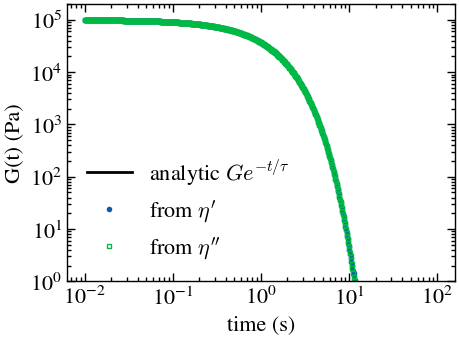

In [3]:
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.loglog(t, G0 * np.exp(-t / tau), "k-", label=r"analytic $Ge^{-t/\tau}$")
ax.loglog(t, g1, "o", ms=3, label=r"from $\eta'$")
ax.loglog(t, g2, "s", ms=3, mfc="none", label=r"from $\eta''$")
ax.set(xlabel="time (s)", ylabel="G(t) (Pa)", ylim=(1e0, 2e5)); ax.legend()
plt.show()

The reconstruction follows the exponential decay over the covered window;
deviations appear only at times outside the measured frequency range
($\sim 1/\omega_\mathrm{max}$ to $\sim 1/\omega_\mathrm{min}$).

## Experimental data: polymer melt, time–temperature superposition

A single frequency sweep spans two or three decades, which limits $G(t)$ to a
similarly narrow window. Time–temperature superposition (Tutorial 4) extends
the spectrum: `CompositeMasterCurve` shifts $G'$ and $G''$ jointly onto one
master curve at 20 °C (Lennon et al., 2023), covering about 15 decades of
reduced frequency $a_T\,\omega$. Reconstructing $G(t)$ from it gives the
relaxation modulus over a correspondingly broad time window.

In [4]:
from piblin.data import Measurement, OneDimensionalCompositeDataset
from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms import CompositeMasterCurve

exp = read_file(DATA / "aresg2_trios_frequency_sweep_tts.txt",
                file_reader=TriosRheoReader, create_composite_datasets=True)
mc = CompositeMasterCurve(n_curves=2, y_quantities=["storage modulus", "loss modulus"],
                          x="angular frequency", state="temperature", state_mode="average",
                          vertical_shift=False, sort_states=True, ref_temp_idx=6)(exp)
w, gp = mc.get_mastercurve("storage modulus").datasets[0].data_arrays[:2]
wb, gpp = mc.get_mastercurve("loss modulus").datasets[0].data_arrays[:2]
gpp = np.exp(np.interp(np.log(w), np.log(wb), np.log(gpp)))  # common frequency grid
master = Measurement(datasets=[OneDimensionalCompositeDataset(
    data_arrays=[w, gp * 1e6, gpp * 1e6],  # MPa -> Pa
    data_array_names=["angular frequency", "storage modulus", "loss modulus"],
    data_array_units=["rad/s", "Pa", "Pa"],
    default_independent_name="angular frequency", default_dependent_name="storage modulus")])
print(f"{len(w)} points, {w.min():.1e}-{w.max():.1e} rad/s")

340 points, 1.4e-05-1.1e+10 rad/s


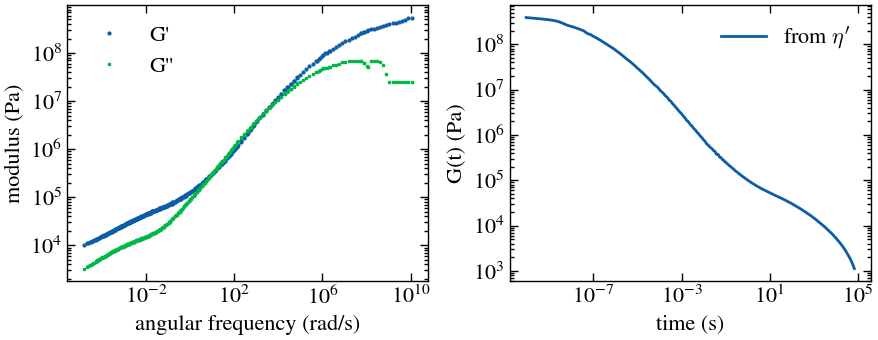

In [5]:
ft = FrequencyToTime()
res = ft(master)
t, g1, g2 = res.datasets[0].data_arrays
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.6))
a.loglog(w, gp * 1e6, "o", ms=2, label="G'"); a.loglog(w, gpp * 1e6, "s", ms=2, label="G''")
a.set(xlabel="angular frequency (rad/s)", ylabel="modulus (Pa)"); a.legend()
b.loglog(t, g1, "-", label=r"from $\eta'$")
b.set(xlabel="time (s)", ylabel="G(t) (Pa)"); b.legend()
plt.tight_layout(); plt.show()

$G(t)$ decays from the glassy short-time response ($\sim 10^8$ Pa) through
the glass transition to a rubbery shoulder around $10^4$–$10^5$ Pa. Because
$G' > G''$ even at the lowest shifted frequency, the master curve does not
reach the terminal regime, and the drop beyond $\sim 10^{4}$ s reflects the
end of the data window rather than terminal flow. The $\eta'$ estimate is the
more robust one for noisy master curves; the $\eta''$ estimate oscillates at
short times and is not shown.

Further options control the low-frequency anchor (`lf_poly_order`,
`lf_fit_decades`), the high-frequency extension (`hf_poly_order`,
`hf_fit_decades`, `hf_ext_decades`), the interpolant
(`interpolation_method="spline"`, `"pchip"` or `"csaps"`), and an optional
single-mode Maxwell terminal tail (`fit_maxwell_tail=True`).

## References

- Ramírez, J. and Tassieri, M., *i-Rheo-Tempo: A model-free, quadrature-free
  reconstruction of the shear relaxation modulus from complex viscosity*,
  *Journal of Rheology* **70**, 1089–1104 (2026).
  DOI: [10.1122/8.0001232](https://doi.org/10.1122/8.0001232).
  Reference implementation: University of Glasgow Research Data,
  [10.5525/gla.researchdata.2230](https://doi.org/10.5525/gla.researchdata.2230).
- Lennon, K. R., McKinley, G. H. and Swan, J. W., *A data-driven method for
  automated data superposition with applications in soft matter science*,
  *Data-Centric Engineering* **4**, e13 (2023).
  DOI: [10.1017/dce.2023.3](https://doi.org/10.1017/dce.2023.3).